In [1]:
#----------------------------------------Notebook for storm time series---------------------------------------

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

import json
import datetime as dt
import matplotlib.pyplot as plt
from tropycal import tracks

In [3]:
#Change basin, storm name, and date for different storm 

In [4]:
basin = tracks.TrackDataset(basin='north_atlantic',include_btk=False)
storm = basin.get_storm(('edouard',2014))
ships = storm.get_ships(dt.datetime(2014, 9, 11, 12))
available_times = storm.search_ships()

--> Starting to read in HURDAT2 data
--> Completed reading in HURDAT2 data (1.65 seconds)


In [5]:
#snapshot of the storm data to verify data is working
output_dict = ships.get_snapshot(hour=48)

# Format nicely for documentation purposes
print(json.dumps(output_dict, indent=4))

{
    "fhr": 48,
    "vmax_noland_kt": 57,
    "vmax_land_kt": 57,
    "storm_type": "TROP",
    "shear_kt": 20,
    "shear_adj_kt": 0,
    "shear_dir": 239,
    "sst_c": 27.6,
    "vmax_pot_kt": 132,
    "200mb_temp_c": -53.6,
    "thetae_dev_c": 9,
    "700_500_rh": 56,
    "model_vortex_kt": 20,
    "850mb_env_vort": 35,
    "200mb_div": 40,
    "700_850_tadv": 14,
    "dist_land_km": 1996,
    "lat": 21.2,
    "lon": -44.5,
    "storm_speed_kt": 11,
    "heat_content": 17
}


In [6]:
#snapshot of the storm data to verify data is working
output_dict = ships.get_ri_prob()

# Format nicely for documentation purposes
print(json.dumps(output_dict, indent=4))

{
    "25kt/24hr": {
        "probability": 30,
        "climo_mean": 11.9,
        "prob / climo": 2.5
    },
    "30kt/24hr": {
        "probability": 17,
        "climo_mean": 7.6,
        "prob / climo": 2.2
    },
    "35kt/24hr": {
        "probability": 8,
        "climo_mean": 4.6,
        "prob / climo": 1.7
    },
    "40kt/24hr": {
        "probability": 7,
        "climo_mean": 3.0,
        "prob / climo": 2.4
    }
}


In [7]:
ds = ships.to_xarray()

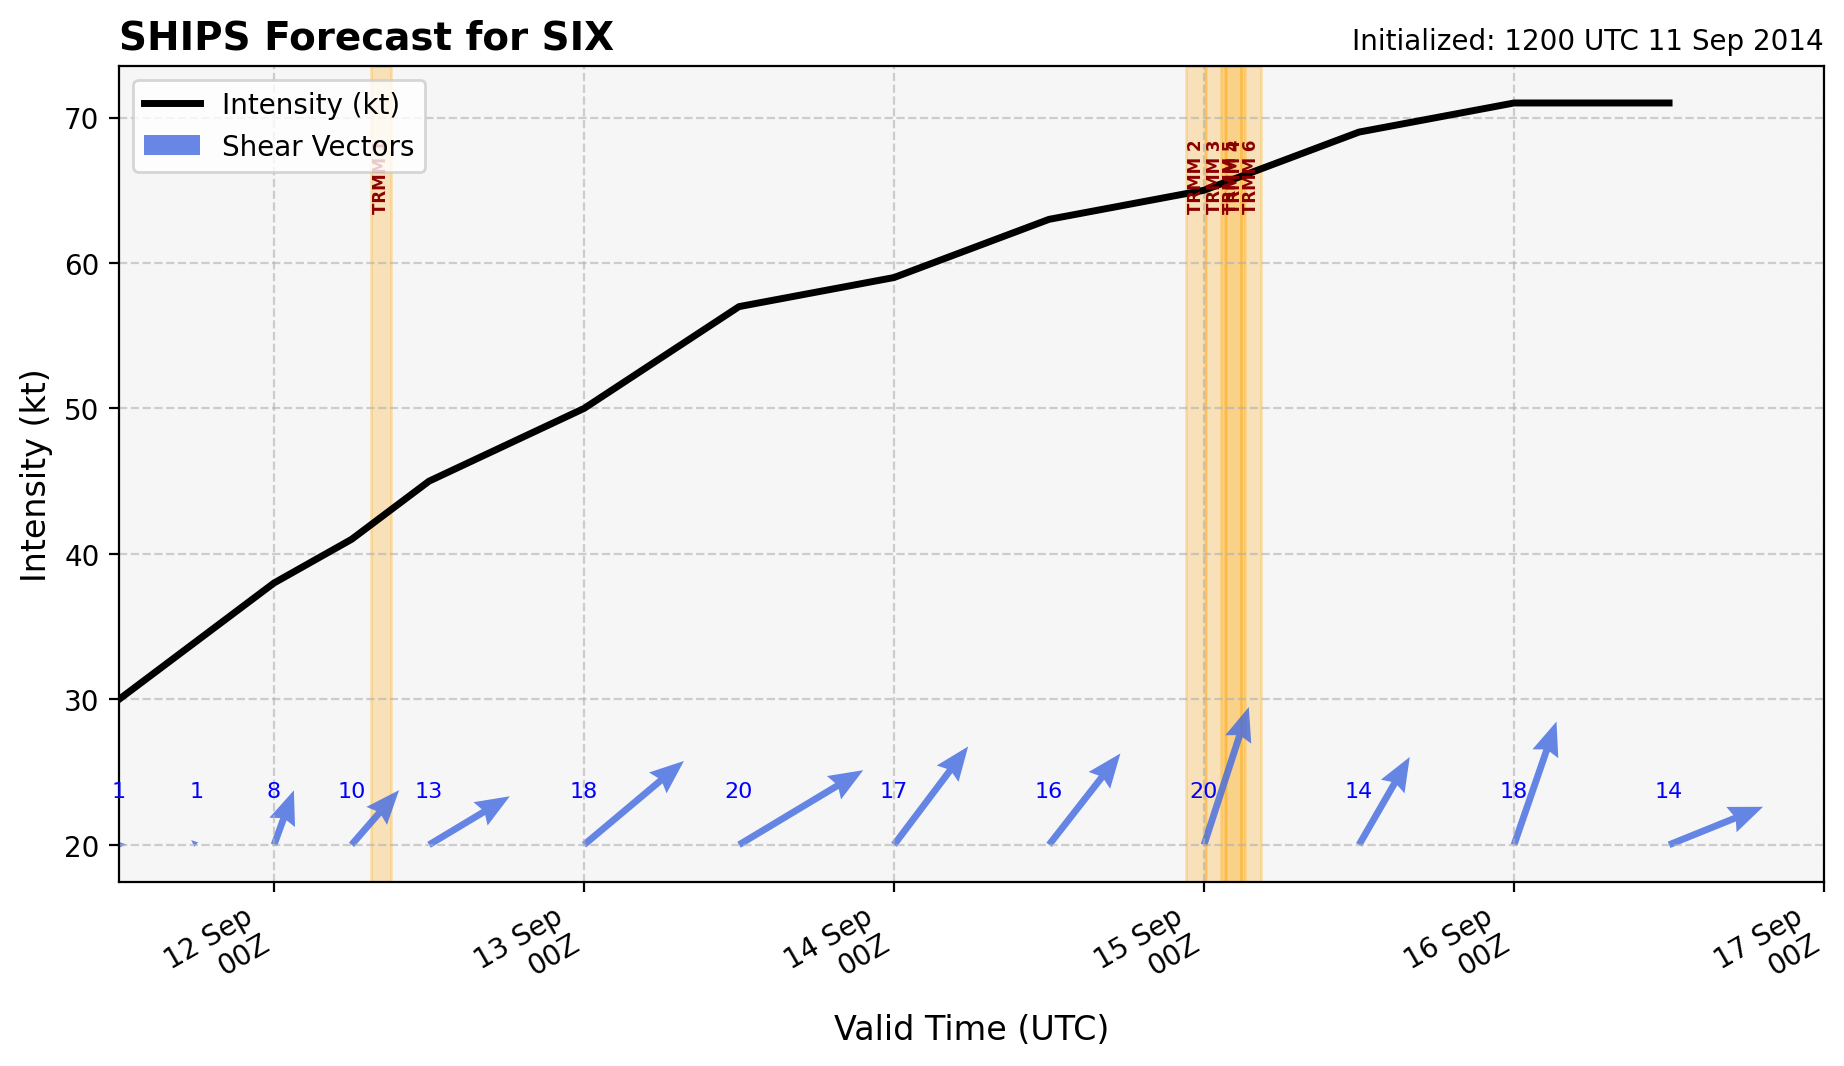

In [8]:
###################                     Forecast for 9/11/2014 12UTC                   #######################

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import datetime as dt

# Create valid datetime array from forecast_init + fhr
valid_times = [ships.attrs['forecast_init'] + dt.timedelta(hours=int(h)) for h in ships.fhr]

# Create figure
fig, ax = plt.subplots(figsize=(11,6), dpi=200)
ax.set_facecolor('#f6f6f6')
ax.grid(True, linestyle="--", alpha=0.6)

# --- Plot intensity line ---
ax.plot(valid_times, ships.vmax_land_kt, color='k', linewidth=2.5, label="Intensity (kt)")

# --- Compute shear vector components ---
u = -ships.shear_kt * np.sin(np.deg2rad(ships.shear_dir))
v = -ships.shear_kt * np.cos(np.deg2rad(ships.shear_dir))

# --- Plot shear arrows near x-axis (fixed y level, e.g. 20 kt) ---
y_shear = np.full_like(ships.shear_kt, 20)
scale_factor = 5.0
ax.quiver(
    valid_times, y_shear,
    u/scale_factor, v/scale_factor,
    color="royalblue", width=0.004, headwidth=4, headlength=5, alpha=0.8,
    label="Shear Vectors"
)

# --- Add shear magnitude labels ---
for t, y, shear in zip(valid_times, y_shear, ships.shear_kt):
    ax.text(t, y + 3, f"{int(shear)}", color="blue",
            fontsize=8, ha="center", va="bottom")

# --- Highlight TRMM overpasses ---
#Change these values if working with a different storm- there will be different TRMM overpasses
trmm_windows = [
    (dt.datetime(2014, 9, 12, 7, 30), dt.datetime(2014, 9, 12, 9, 5)),
    (dt.datetime(2014, 9, 14, 22, 34), dt.datetime(2014, 9, 15, 0, 8)),
    (dt.datetime(2014, 9, 15, 0, 6), dt.datetime(2014, 9, 15, 1, 40)),
    (dt.datetime(2014, 9, 15, 1, 38), dt.datetime(2014, 9, 15, 3, 12)),
    (dt.datetime(2014, 9, 15, 1, 18), dt.datetime(2014, 9, 15, 2, 52)),
    (dt.datetime(2014, 9, 15, 2, 50), dt.datetime(2014, 9, 15, 4, 24)),
]

for i, (start, end) in enumerate(trmm_windows, 1):
    ax.axvspan(start, end, color="orange", alpha=0.25, zorder=-1)
    # Place vertical label
    ax.text(start + (end-start)/2, ax.get_ylim()[1]-5,
            f"TRMM {i}", color="darkred", fontsize=6,
            ha="center", va="top", fontweight="bold", rotation=90)

# --- Axis formatting ---
ax.set_ylabel("Intensity (kt)", fontsize=12)
ax.set_xlabel("Valid Time (UTC)", fontsize=12)

# Format x-axis ticks
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%HZ"))
fig.autofmt_xdate()

# Extend x-axis out to Sept 18, 2014
ax.set_xlim([ships.attrs['forecast_init'], dt.datetime(2014, 9, 17, 0)])

# --- Title & legend ---
ax.set_title(f"SHIPS Forecast for {ships.attrs['storm_name']}", 
             loc="left", fontsize=14, fontweight="bold")
ax.set_title(f"Initialized: {ships.attrs['forecast_init'].strftime('%H%M UTC %d %b %Y')}", 
             loc="right", fontsize=10)

ax.legend(loc="upper left")
plt.show()


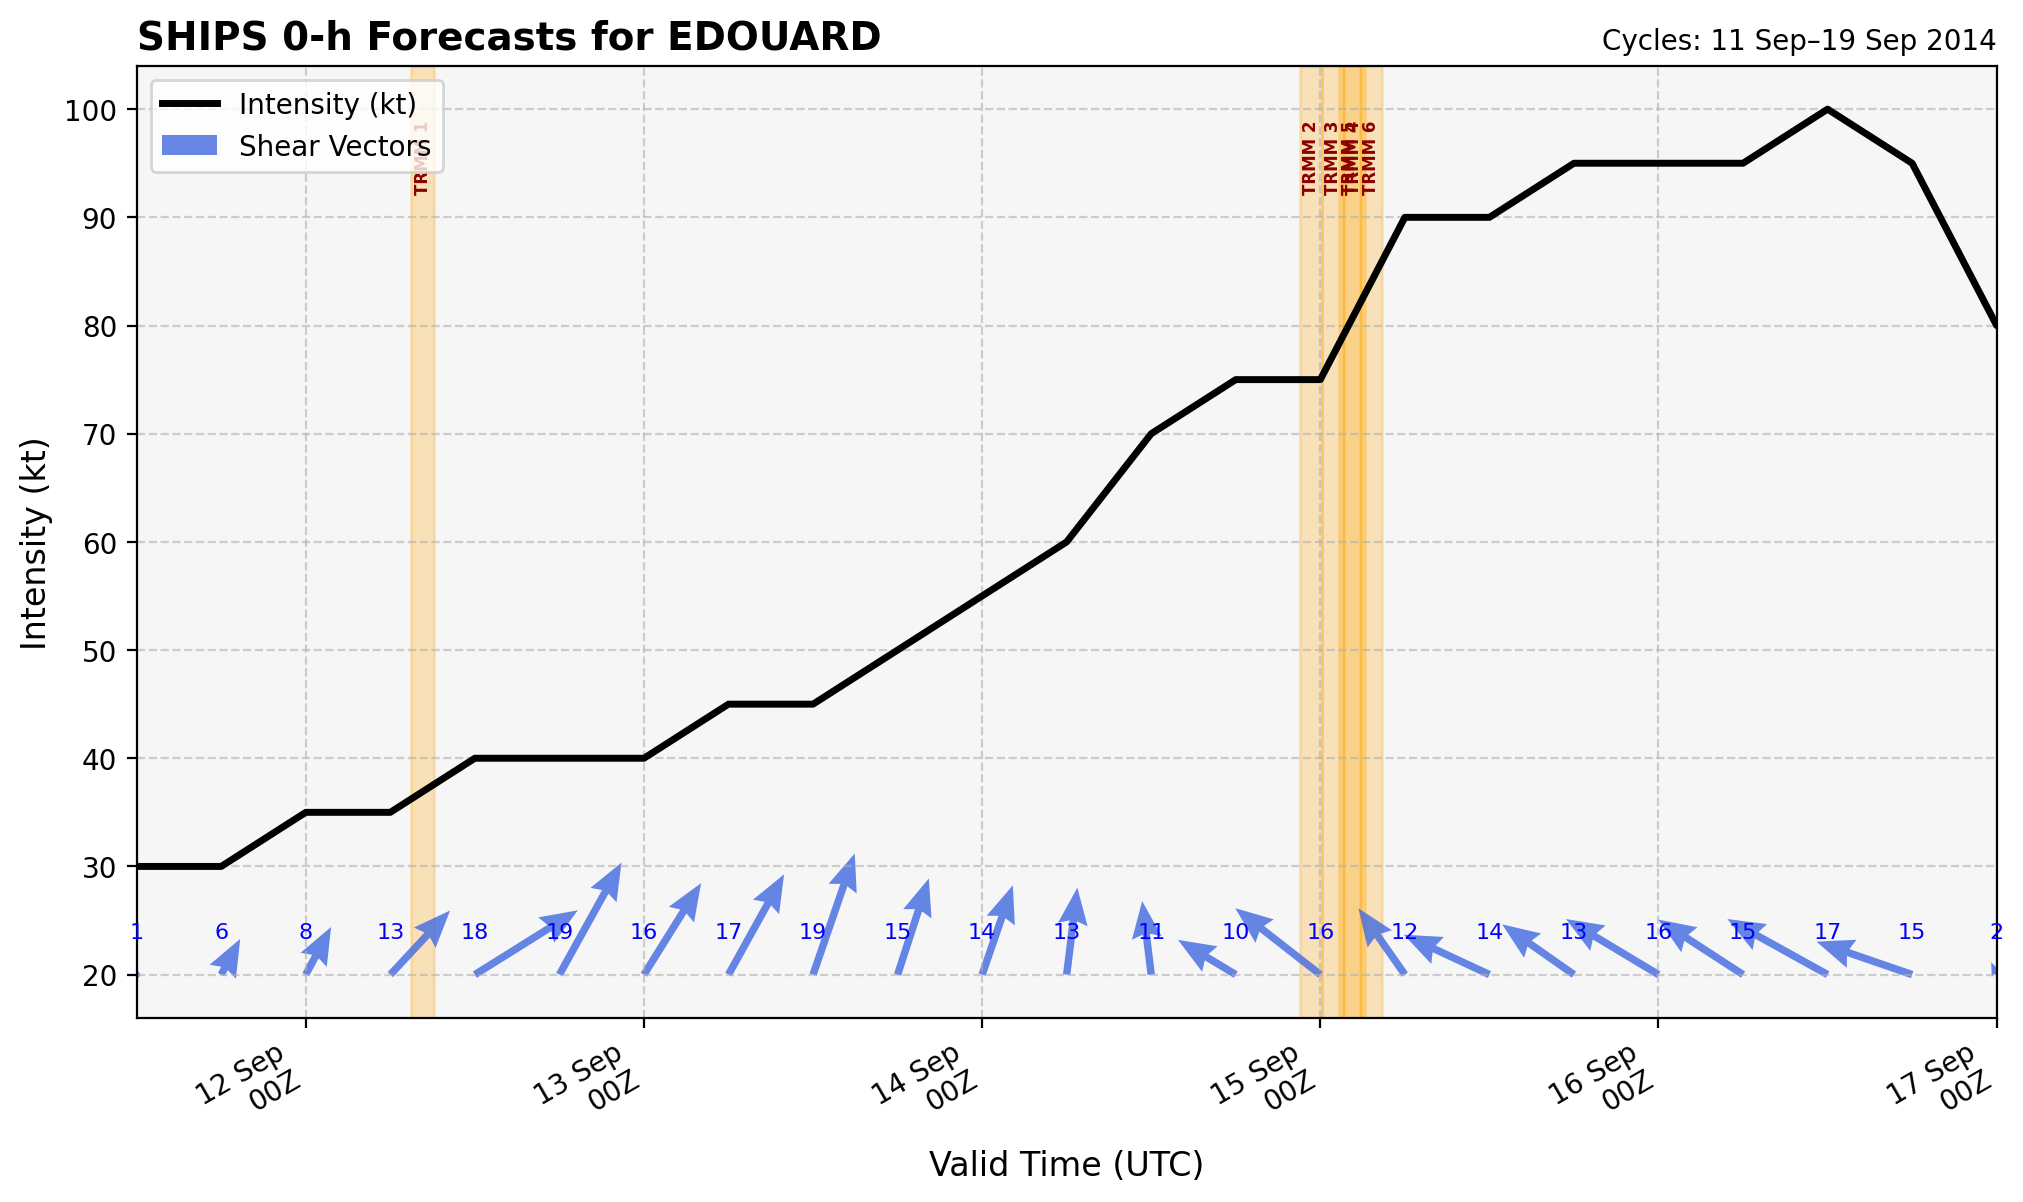

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import datetime as dt

# --- Get all available SHIPS forecast initializations for Edouard ---
available_times = storm.search_ships()

valid_times = []
intensity = []
shear_kt = []
shear_dir = []

for t in available_times:
    ships = storm.get_ships(t)
    valid_times.append(ships.attrs['forecast_init'])
    intensity.append(ships.vmax_land_kt[ships.fhr == 0][0])
    shear_kt.append(ships.shear_kt[ships.fhr == 0][0])
    shear_dir.append(ships.shear_dir[ships.fhr == 0][0])

# --- Compute shear vector components ---
u = -np.array(shear_kt) * np.sin(np.deg2rad(shear_dir))
v = -np.array(shear_kt) * np.cos(np.deg2rad(shear_dir))

# --- Plot ---
fig, ax = plt.subplots(figsize=(12,7), dpi=200)   # made a little taller
ax.set_facecolor('#f6f6f6')
ax.grid(True, linestyle="--", alpha=0.6)

# Intensity line
ax.plot(valid_times, intensity, color='k', linewidth=2.5, label="Intensity (kt)")

# Shear vectors at fixed y
y_shear = np.full_like(shear_kt, 20)
scale_factor = 5.0
ax.quiver(
    valid_times, y_shear,
    u/scale_factor, v/scale_factor,
    color="royalblue", width=0.004, headwidth=4, headlength=5, alpha=0.8,
    label="Shear Vectors"
)

# Shear magnitude labels
plot_end = dt.datetime(2014, 9, 17, 0)

for t, y, shear in zip(valid_times, y_shear, shear_kt):
    if t <= plot_end:  # only include values within x-axis limit
        ax.text(t, y + 3, f"{int(shear)}", color="blue",
                fontsize=8, ha="center", va="bottom")

# TRMM overpasses (same as before)
trmm_windows = [
    (dt.datetime(2014, 9, 12, 7, 30), dt.datetime(2014, 9, 12, 9, 5)),
    (dt.datetime(2014, 9, 14, 22, 34), dt.datetime(2014, 9, 15, 0, 8)),
    (dt.datetime(2014, 9, 15, 0, 6), dt.datetime(2014, 9, 15, 1, 40)),
    (dt.datetime(2014, 9, 15, 1, 38), dt.datetime(2014, 9, 15, 3, 12)),
    (dt.datetime(2014, 9, 15, 1, 18), dt.datetime(2014, 9, 15, 2, 52)),
    (dt.datetime(2014, 9, 15, 2, 50), dt.datetime(2014, 9, 15, 4, 24)),
]

for i, (start, end) in enumerate(trmm_windows, 1):
    ax.axvspan(start, end, color="orange", alpha=0.25, zorder=-1)
    ax.text(start + (end-start)/2, ax.get_ylim()[1]-5,
            f"TRMM {i}", color="darkred", fontsize=6,
            ha="center", va="top", fontweight="bold", rotation=90)

# --- Axis formatting ---
ax.set_ylabel("Intensity (kt)", fontsize=12)
ax.set_xlabel("Valid Time (UTC)", fontsize=12)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%HZ"))
fig.autofmt_xdate()

ax.set_xlim([min(valid_times), dt.datetime(2014, 9, 17, 0)])

# Expand y-limits so shear labels fit
ymin, ymax = ax.get_ylim()
ax.set_ylim(ymin, ymax)

# --- Title & legend ---
ax.set_title(f"SHIPS 0-h Forecasts for {ships.attrs['storm_name']}", 
             loc="left", fontsize=14, fontweight="bold")
ax.set_title(f"Cycles: {available_times[0].strftime('%d %b')}–{available_times[-1].strftime('%d %b %Y')}", 
             loc="right", fontsize=10)

ax.legend(loc="upper left")
plt.show()
